# **AE complejo: objetivo del notebook**

Este notebook entrena un autoencoder convolucional para reconstruir imágenes faciales de `64x64` píxeles en escala de grises y estudia hasta qué punto puede generar imágenes nuevas. Primero se prepara un conjunto de entrenamiento y otro de validación; después se entrena el AE, se inspeccionan sus reconstrucciones, se muestrea el espacio latente y se calcula el FID de las imágenes generadas.

La diferencia clave es la siguiente: un AE aprende a reconstruir, pero no aprende explícitamente una distribución probabilística del latente. Por eso la fase de generación requiere comprobar si la aproximación `z ~ N(0, I)` es razonable para este modelo.


---

In [60]:
%pip install "torchmetrics[image]"
%pip install opencv-python
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install tensorflow
%pip install pytorch

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl (5.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.16.2 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.15.3 which is incompatible.

In [61]:
import os
import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

---

## **1. Carga de las imágenes**

In [62]:
# El dataset contiene 30.000 imágenes numeradas de 0.jpg a 29999.jpg.
DATASET_DIR = "data/images"
IMG_SIZE = 64
TOTAL_IMAGES = 30000

# Reservamos el tensor en uint8 para no duplicar memoria antes de normalizar.
images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

In [63]:
# Cargamos en escala de grises porque la submission usa un solo canal.
loaded_count = 0

for i in range(TOTAL_IMAGES):
    filename = f"{i}.jpg"
    filepath = os.path.join(DATASET_DIR, filename)
    
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise FileNotFoundError(f"No se pudo cargar la imagen: {filepath}")
    
    # Se conserva la resolución original cuando ya es 64x64; en otro caso se redimensiona (no debería darse).
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        
    images[i] = img
    loaded_count += 1

print(f"Total cargado: {loaded_count} imágenes")

Total cargado: 30000 imágenes


In [64]:
# Verificamos forma, tipo y rango antes de normalizar para detectar datos corruptas.
print(f"Forma del tensor: {images.shape}")          # Esperado: (30000, 64, 64)
print(f"Tipo de dato:     {images.dtype}")          # Esperado: uint8
print(f"Valor mínimo:     {images.min()}")          # Esperado: 0 o cercano 
print(f"Valor máximo:     {images.max()}")          # Esperado: 255 o cercano 

Forma del tensor: (30000, 64, 64)
Tipo de dato:     uint8
Valor mínimo:     0
Valor máximo:     255


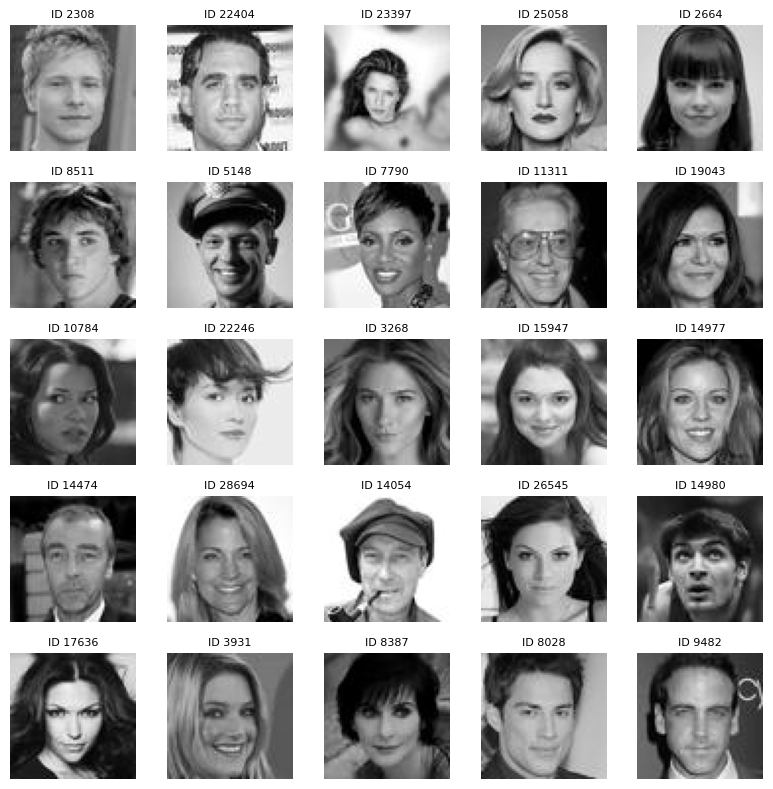

In [65]:
# Visualización rápida
fig, axes = plt.subplots(5, 5, figsize=(8, 8))

# Esta semilla solo controla qué ejemplos se muestran, no el split ni el entrenamiento.
np.random.seed(42)
sample_indices = np.random.choice(TOTAL_IMAGES, size=25, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"ID {idx}", fontsize=8)

plt.tight_layout()
plt.show()

---

## **2. Implementación del AE**

El modelo es un AE determinista formado por un encoder convolucional, un vector latente de 256 dimensiones y un decoder convolucional más ancho y profundo. El encoder comprime cada imagen de `64x64x1` hasta un mapa espacial de `4x4` y después hasta el vector `z`; el decoder realiza el recorrido inverso y produce una imagen en `[0, 1]` mediante una salida `sigmoid`.

La comparación mantiene intactos el encoder, el latente estandarizado y la función de pérdida. El único cambio experimental está en el decoder: cada resolución tiene ahora dos convoluciones consecutivas y más filtros (`256, 128, 96, 64`), para aumentar la capacidad de reconstrucción especialmente en las resoluciones altas.


In [66]:
# La misma semilla fija el split, el shuffle y las operaciones de TensorFlow.
SEED = 1234
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [67]:
# Normalizamos a [0,1] y separamos 27.000 imágenes para train y 3.000 para validación.
# La validación no se usa para actualizar pesos ni para generar la submission.

x_data = images.astype("float32") / 255.0
x_data = np.expand_dims(x_data, axis=-1)  # (30000, 64, 64, 1)

# La partición se realiza sobre índices para conservar la correspondencia con las imágenes originales.
val_size = int(0.10 * len(x_data))
# Se barajan índices
indices = np.random.permutation(len(x_data))
train_idx, val_idx = indices[val_size:], indices[:val_size]

x_train = x_data[train_idx]
x_val = x_data[val_idx]

print(f"Conjunto de entrenamiento: {x_train.shape}")
print(f"Conjunto de validación:    {x_val.shape}")

Conjunto de entrenamiento: (27000, 64, 64, 1)
Conjunto de validación:    (3000, 64, 64, 1)


In [68]:
# Parámetros y encoder convolucional. El latente se estandariza antes de construir el decoder.
LATENT_DIM = 256
BATCH_SIZE = 128
EPOCHS = 40

encoder_inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 1),
    name="encoder_input"
)

# Cada convolución reduce la resolución a la mitad y aumenta la capacidad de representación.
x = layers.Conv2D(32, kernel_size=4, strides=2, padding="same", use_bias=False)(encoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(64, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(256, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

# La activación 4x4x256 contiene la representación espacial comprimida.
x = layers.Flatten()(x)

# Proyección final a 256 coordenadas latentes antes de la estandarización.
z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector"
)(x)

# Normalización sin centro ni escala: aproxima media 0 y varianza 1 por dimensión.
z = layers.BatchNormalization(
    center=False,
    scale=False,
    name="latent_standardization"
)(z)

encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")

In [69]:
# Decoder independiente: recibe únicamente z y no necesita una imagen real ni skip connections.
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")

# Expandimos z al mapa espacial más pequeño del decoder.
x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

# Cada bloque duplica la resolución y aplica dos Conv2D+BN+LeakyReLU.
# Las resoluciones son 8, 16, 32 y 64; se aumenta la capacidad del decoder.
for filters in (256, 128, 96, 64):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

# La última convolución produce una única intensidad por píxel en [0, 1].
decoder_outputs = layers.Conv2D(
    1,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="decoder_output"
)(x)

decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")


In [70]:
# Modelo completo para reconstrucción: imagen -> encoder -> z -> decoder -> imagen.
encoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="autoencoder_input")
autoencoder = keras.Model(
    encoder_input,
    decoder_ae(encoder_ae(encoder_input)),
    name="autoencoder"
)

### **Decisiones de arquitectura**

- **Encoder:** se mantiene sin cambios: cuatro bloques `Conv2D` con filtros `32, 64, 128 y 256`, reducción `64 -> 32 -> 16 -> 8 -> 4`, cuello latente de `256` dimensiones y `BatchNormalization(center=False, scale=False)` después de la `Dense`.
- **Decoder ensanchado:** se mantiene la proyección inicial `Dense -> 4x4x256` y el recorrido por `UpSampling2D` bilineal.
- **Dos convoluciones por resolución:** en cada escala (`8, 16, 32 y 64`) se aplican dos secuencias `Conv2D + BatchNormalization + LeakyReLU`. Esto aumenta la profundidad efectiva y permite refinar los detalles después de cada cambio de resolución.
- **Más filtros:** las escalas utilizan `(256, 128, 96, 64)` en lugar de `(128, 64, 32, 16)`. El experimento busca medir exclusivamente el efecto de dar más capacidad al decoder, sin modificar el encoder ni el espacio latente.
- **Sin conexiones residuales:** se empieza con bloques secuenciales simples para mantener la comparación interpretable y evitar introducir otra fuente de mejora.
- **Salida:** la convolución final mantiene `sigmoid`, por lo que las imágenes reconstruidas y generadas siguen estando en `[0, 1]`.


In [71]:
# Pérdida combinada: L1 para precisión de píxel y SSIM para estructura local.
# Se calcula por batch y se promedian los términos.
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    ssim = 1.0 - tf.reduce_mean(
        tf.image.ssim(y_true, y_pred, max_val=1.0)
    )
    return 0.5 * l1 + 0.5 * ssim


# Adam ajusta todos los pesos del encoder y decoder.
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=ssim_l1_loss
)


def make_dataset(x_array, training=True):
    dataset = tf.data.Dataset.from_tensor_slices((x_array, x_array))
    # Solo train recibe shuffle y flip; validation permanece determinista.
    # Estamos haciendo data augmentation solo en el conjunto de entrenamiento para mejorar la generalización.
    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(x_array), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        dataset = dataset.map(
            lambda image, target: (
                tf.image.random_flip_left_right(image),
                target
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )
        # Entrada y objetivo son la misma imagen volteada: el AE aprende invariancia al flip.
        dataset = dataset.map(
            lambda image, _: (image, image),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(x_train, training=True)
val_ds = make_dataset(x_val, training=False)

callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-5,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

history_ae = autoencoder.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks
)

Epoch 1/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 119s 529ms/step - loss: 0.3575 - val_loss: 0.4492 - learning_rate: 0.0010
Epoch 2/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 119s 565ms/step - loss: 0.2301 - val_loss: 0.2811 - learning_rate: 0.0010
Epoch 3/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 141s 666ms/step - loss: 0.1975 - val_loss: 0.1997 - learning_rate: 0.0010
Epoch 4/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 140s 663ms/step - loss: 0.1800 - val_loss: 0.1926 - learning_rate: 0.0010
Epoch 5/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 143s 677ms/step - loss: 0.1677 - val_loss: 0.1982 - learning_rate: 0.0010
Epoch 6/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 162s 767ms/step - loss: 0.1597 - val_loss: 0.1797 - learning_rate: 0.0010
Epoch 7/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 201s 952ms/step - loss: 0.1541 - val_loss: 0.1632 - learning_rate: 0.0010
Epoch 8/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 210s 997ms/step - loss: 0.1483 - val_loss: 0.1508 - learning_rate: 0.0010
Epoch 9/40
211/211 ━━━━━━━━━━━━━━━━━━━━ 184s 872ms/step - loss: 0.1437 - val_loss: 0.151

In [72]:
# Resumen de la mejor epoch según la pérdida de validación.
metrics_history = history_ae.history
best_epoch = int(np.argmin(metrics_history["val_loss"]))

print(f"Mejor época según val_loss: {best_epoch + 1}")
print(f"Train loss:      {metrics_history['loss'][best_epoch]:.4f}")
print(f"Validation loss: {metrics_history['val_loss'][best_epoch]:.4f}")

Mejor época según val_loss: 36
Train loss:      0.1033
Validation loss: 0.1024


### **Decisiones de pérdida y entrenamiento**

La pérdida es la media de dos objetivos complementarios:

- **L1:** penaliza el error absoluto por píxel y tiende a conservar bordes sin sobrerreaccionar a errores aislados (evitamos el MSE).
- **SSIM:** compara estructura local, luminancia y contraste; ayuda a que las reconstrucciones mantengan la estructura aunque no coincidan exactamente en cada píxel.

Ambos términos tienen peso `0.5`. El `RandomFlip` horizontal se aplica únicamente al conjunto de entrenamiento y la imagen volteada se usa también como objetivo, de forma que la transformación no introduce un objetivo inconsistente. La validación no se aumenta ni se baraja con transformaciones. `ReduceLROnPlateau` reduce la tasa de aprendizaje si `val_loss` deja de mejorar y `EarlyStopping` restaura los mejores pesos.


---

## **3. Resultados del entrenamiento**

Las siguientes celdas muestran la evolución de la pérdida y las reconstrucciones del modelo con el decoder ensanchado. Al cambiar la capacidad del decoder, las métricas y las imágenes guardadas anteriormente dejan de ser comparables: es necesario volver a ejecutar el entrenamiento desde esta arquitectura para obtener los resultados de esta variante.


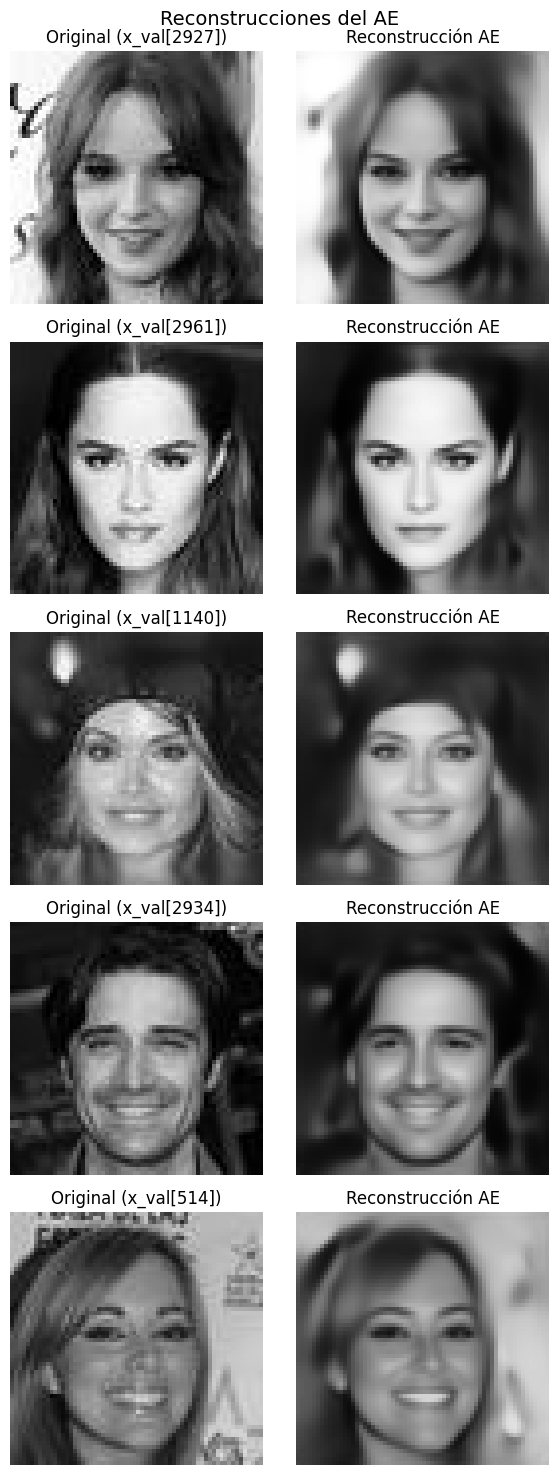

In [73]:
# Evaluación sobre validación: estas imágenes no se usan para entrenar ni generar la submission.
COMPARISON_SEED = SEED
comparison_rng = np.random.default_rng(COMPARISON_SEED)
# Seleccionamos ejemplos no repetidos de validación.
comparison_indices = comparison_rng.choice(len(x_val), size=5, replace=False)
x_val_samples = x_val[comparison_indices]

ae_reconstructions = autoencoder.predict(x_val_samples, verbose=0)

fig, axes = plt.subplots(5, 2, figsize=(6, 15))
fig.suptitle("Reconstrucciones del AE", fontsize=14)

for row, (original, reconstruction, sample_index) in enumerate(
    zip(x_val_samples, ae_reconstructions, comparison_indices)
):
    axes[row, 0].imshow(original[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original (x_val[{sample_index}])")
    axes[row, 1].imshow(reconstruction[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Reconstrucción AE")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [74]:
# Resumen de la mejor epoch según la pérdida de validación.
metrics_history = history_ae.history
best_epoch = int(np.argmin(metrics_history["val_loss"]))

print(f"Mejor época según val_loss: {best_epoch + 1}")
print(f"Train loss:      {metrics_history['loss'][best_epoch]:.4f}")
print(f"Validation loss: {metrics_history['val_loss'][best_epoch]:.4f}")

Mejor época según val_loss: 36
Train loss:      0.1033
Validation loss: 0.1024


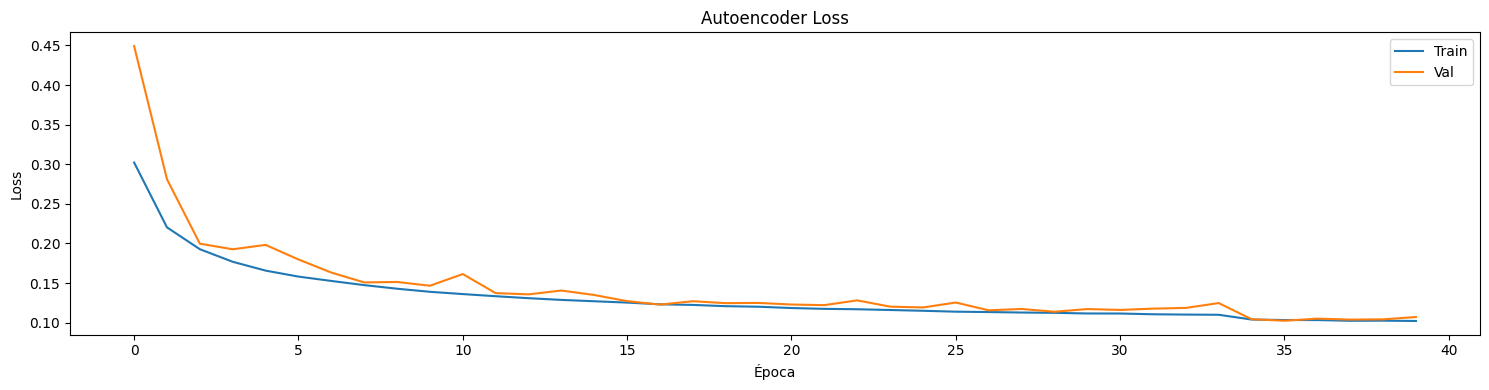

In [75]:
# Curvas para detectar convergencia y posible overfitting.
fig, axes = plt.subplots(1, figsize=(15, 4))

axes.plot(history_ae.history["loss"], label="Train")
axes.plot(history_ae.history["val_loss"], label="Val")
axes.set_title("Autoencoder Loss")
axes.set_xlabel("Época")
axes.set_ylabel("Loss")
axes.legend()

plt.tight_layout()
plt.show()

---

## **4. Generación y creación de la submission**

El decoder ensanchado sigue utilizándose como único modelo generativo. Se generan `200` vectores latentes con una normal estándar y se decodifican directamente:

```text
z ~ N(0, I) -> decoder_ae ensanchado -> imagen
```

El experimento conserva el mismo encoder, la misma estandarización latente, la misma loss y el mismo protocolo de generación. Por tanto, la comparación con la versión anterior está diseñada para aislar el efecto de aumentar la profundidad y el número de filtros del decoder.


In [76]:
# Número de filas para la submission.
N_SAMPLES = 200
SAMPLE_SEED = 1234

sample_rng = np.random.default_rng(SAMPLE_SEED)
z_samples_ae = sample_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_SAMPLES, LATENT_DIM)
).astype(np.float32)

print(f"Muestras latentes generadas: {z_samples_ae.shape}")

Muestras latentes generadas: (200, 256)


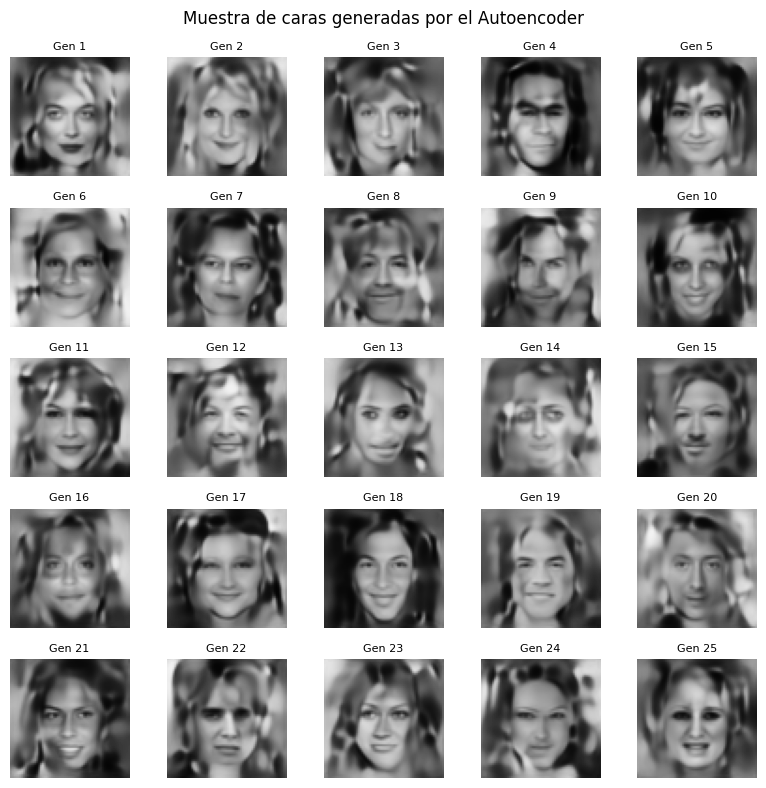

In [77]:
# El decoder ensanchado devuelve float32 en [0, 1]; aquí se cuantiza para visualizar en [0, 255].
generated_float = decoder_ae.predict(
    z_samples_ae,
    batch_size=N_SAMPLES,
    verbose=0
)
generated_imgs = np.clip(
    np.round(generated_float * 255.0), 0, 255
).astype(np.uint8)
generated_imgs = np.squeeze(generated_imgs, axis=-1)

assert generated_float.shape == (N_SAMPLES, IMG_SIZE, IMG_SIZE, 1)
assert np.isfinite(generated_float).all()
assert generated_float.min() >= 0.0 and generated_float.max() <= 1.0

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
fig.suptitle("Muestra de caras generadas por el Autoencoder", fontsize=12)
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_imgs[i], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"Gen {i + 1}", fontsize=8)
plt.tight_layout()
plt.show()


In [78]:
# Exportación de la variante con decoder ensanchado: solo estas 200 imágenes generadas se pasan al formato de entrega.
flat_pixels = generated_imgs.reshape(N_SAMPLES, IMG_SIZE * IMG_SIZE)
df_submission = pd.DataFrame(
    flat_pixels,
    columns=[str(i) for i in range(IMG_SIZE * IMG_SIZE)]
)
df_submission.insert(0, "Usage", "Public")
df_submission.insert(0, "ID", range(1, N_SAMPLES + 1))

assert df_submission.shape == (N_SAMPLES, 2 + IMG_SIZE * IMG_SIZE)
assert df_submission.isnull().sum().sum() == 0
assert df_submission.iloc[:, 2:].values.min() >= 0
assert df_submission.iloc[:, 2:].values.max() <= 255
assert list(df_submission.columns[:3]) == ["ID", "Usage", "0"]

csv_filename = "submission_ae_complex2.csv"
df_submission.to_csv(csv_filename, index=False)
print(f"Archivo guardado como '{csv_filename}' | forma: {df_submission.shape}")


Archivo guardado como 'submission_ae_complex2.csv' | forma: (200, 4098)


---

## **5. Evaluación FID del AE con decoder ensanchado**

El FID mantiene exactamente el protocolo de la variante anterior: la referencia real es `x_val`, se usan hasta `512` imágenes, se convierten las imágenes grayscale a `uint8`, se replica el canal gris a RGB y se calculan características Inception con `feature=2048`.

El resultado de FID que aparecía antes correspondía al decoder anterior y no debe reutilizarse para esta variante. Después de entrenar el nuevo decoder, hay que ejecutar de nuevo esta sección y comparar el valor obtenido manteniendo la misma referencia, el mismo número de muestras y el mismo preprocesado.


In [79]:
FID_SEED = SEED
FID_BATCH_SIZE = 64
# Limitamos a 512 para mantener el coste controlado y usar el mismo protocolo comparativo.
FID_NUM_IMAGES = min(len(x_val), 512)

device = "cpu"

def prepare_images_for_fid(images):
    images = np.asarray(images)
    
    # Si la imagen ya es uint8, asumimos que está en [0, 255] y no la tocamos
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
        
    # Asegurar que tenga dimensión de canal (por si viene en 3D: N, H, W)
    if images.ndim == 3:
        images = images[..., np.newaxis]
        
    images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(images)


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    # Inception convierte cada imagen en un vector de características; FID compara sus medias/covarianzas.
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(device)
    real_images = prepare_images_for_fid(real_images)
    generated_images = prepare_images_for_fid(generated_images)

    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(device), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(device), real=False)
        return fid.compute().item()


# Referencia real: únicamente validación; las muestras proceden del decoder ensanchado a partir de z~N(0,I).
real_images = x_val[:FID_NUM_IMAGES]
fid_rng = np.random.default_rng(FID_SEED)
z_fid = fid_rng.normal(
    0.0, 1.0, size=(FID_NUM_IMAGES, LATENT_DIM)
).astype(np.float32)
generated_ae_fid = decoder_ae.predict(
    z_fid,
    batch_size=FID_BATCH_SIZE,
    verbose=0
)

fid_ae = calculate_fid(
    generated_ae_fid,
    real_images,
    batch_size=FID_BATCH_SIZE
)
print(f"FID AE ({FID_NUM_IMAGES} imágenes, dispositivo={device}): {fid_ae:.4f}")


FID AE (512 imágenes, dispositivo=cpu): 93.6005


In [80]:
FID_NUM_IMAGES = 200

# Referencia real: únicamente validación; las muestras proceden del decoder ensanchado a partir de z~N(0,I).
real_images = x_val[:FID_NUM_IMAGES]
fid_rng = np.random.default_rng(FID_SEED)
z_fid = fid_rng.normal(
    0.0, 1.0, size=(FID_NUM_IMAGES, LATENT_DIM)
).astype(np.float32)
generated_ae_fid = decoder_ae.predict(
    z_fid,
    batch_size=FID_BATCH_SIZE,
    verbose=0
)

fid_ae = calculate_fid(
    generated_ae_fid,
    real_images,
    batch_size=FID_BATCH_SIZE
)
print(f"FID AE ({FID_NUM_IMAGES} imágenes, dispositivo={device}): {fid_ae:.4f}")

FID AE (200 imágenes, dispositivo=cpu): 108.3406


In [82]:
FID_NUM_IMAGES = 3000

# Referencia real: únicamente validación; las muestras proceden del decoder ensanchado a partir de z~N(0,I).
real_images = x_val[:FID_NUM_IMAGES]
fid_rng = np.random.default_rng(FID_SEED)
z_fid = fid_rng.normal(
    0.0, 1.0, size=(FID_NUM_IMAGES, LATENT_DIM)
).astype(np.float32)
generated_ae_fid = decoder_ae.predict(
    z_fid,
    batch_size=FID_BATCH_SIZE,
    verbose=0
)

fid_ae = calculate_fid(
    generated_ae_fid,
    real_images,
    batch_size=FID_BATCH_SIZE
)
print(f"FID AE ({FID_NUM_IMAGES} imágenes, dispositivo={device}): {fid_ae:.4f}")

FID AE (3000 imágenes, dispositivo=cpu): 79.8759


---

## **6. ¿Qué aporta la estandarización del latente?**

Un AE convencional tiene este recorrido:

$$x \longrightarrow 	ext{Encoder} \longrightarrow z \longrightarrow 	ext{Decoder} \longrightarrow \hat{x}$$

pero no impone por sí mismo que los códigos `z` sigan una normal estándar. Si las coordenadas tienen desplazamientos o escalas diferentes, muestrear `N(0, I)` puede producir muchos vectores fuera de las regiones donde el decoder fue entrenado.

Lo que muestran los resultados a continuación:

- media absoluta media por dimensión: `0.042`;
- desviación estándar mínima/mediana/máxima: `0.978 / 0.992 / 1.011`;
- correlación absoluta media entre dimensiones: `0.060`;
- `E[||z||²] = 126.5`, frente a `256` para `N(0, I)` en 256 dimensiones.

Estas cifras indican que la aproximación es razonable: las escalas están cerca de uno, las medias son pequeñas y las correlaciones son bajas. No obstante, la normalización por batch no garantiza independencia completa ni convierte el AE en un VAE; por eso el FID sigue siendo una comprobación experimental necesaria.

El resultado principal guardado fue `FID = 111.7476` para `tau=1` en el muestreo estándar. Al reducir la escala del ruido se obtuvieron, como referencia, `123.1801` (`tau=0.5`), `114.6863` (`tau=0.7`), `110.7221` (`tau=0.85`) y `109.8950` (`tau=1.0`). La comparación debería hacerse siempre con la misma referencia, mismo número de imágenes y preprocesado.


In [83]:
z_train = encoder_ae.predict(x_train, batch_size=256, verbose=0)
std = z_train.std(0)
corr = np.corrcoef(z_train.T)
off = corr[~np.eye(LATENT_DIM, dtype=bool)]
print(f"|media| por dim: {np.abs(z_train.mean(0)).mean():.3f} (N(0,I): 0)")
print(f"std por dim  min/mediana/max: {std.min():.3f} / {np.median(std):.3f} / {std.max():.3f} (N(0,I): 1)")
print(f"|corr| media entre dims: {np.abs(off).mean():.3f} (N(0,I): 0)")
print(f"E||z||^2: {(z_train**2).sum(1).mean():.1f} (N(0,I): {LATENT_DIM})")

rng = np.random.default_rng(SEED)
# Para comparar N(0,I) con una gaussiana ajustada.
z_diag = rng.multivariate_normal(z_train.mean(0), np.cov(z_train.T), size=512).astype(np.float32)
print("FID gaussiana ajustada:", calculate_fid(decoder_ae.predict(z_diag, verbose=0), real_images))

# Techo aproximado de reconstrucción
idx = rng.choice(len(x_train), 512, replace=False)
print("FID reconstrucciones  :", calculate_fid(autoencoder.predict(x_train[idx], verbose=0), real_images))

# Sensibilidad del FID a la escala del ruido normal, manteniendo la misma referencia.
for tau in (0.5, 0.7, 0.85, 1.0):
    z = tau * rng.normal(size=(512, LATENT_DIM)).astype(np.float32)
    print(f"tau={tau}:", calculate_fid(decoder_ae.predict(z, verbose=0), real_images))

|media| por dim: 0.072 (N(0,I): 0)
std por dim  min/mediana/max: 0.958 / 0.980 / 1.004 (N(0,I): 1)
|corr| media entre dims: 0.048 (N(0,I): 0)
E||z||^2: 247.9 (N(0,I): 256)
FID gaussiana ajustada: 82.98065185546875
FID reconstrucciones  : 66.22232818603516
tau=0.5: 82.38245391845703


KeyboardInterrupt: 

In [84]:
# Guardar los modelos de la variante con decoder ensanchado para reutilizarlos sin reentrenar.
os.makedirs("checkpoints", exist_ok=True)
autoencoder.save("checkpoints/ae_complex2.keras")
encoder_ae.save("checkpoints/encoder_complex2.keras")
decoder_ae.save("checkpoints/decoder_complex2.keras")
print("Modelos guardados en checkpoints/")

Modelos guardados en checkpoints/
